# Initial EDA

The code below serves as a setup code block to load all the libraries and initialises the directory paths:

In [1]:
# Imports
import math
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Initialize the directory paths
ROOT_DIRECTORY = "../dataset/"
CLEANED_DIRECTORY = ROOT_DIRECTORY + "0_cleaned/"

# Set decimal points
pd.set_option('display.float_format', lambda x: '%.3f' % x)

## Step 1: Understanding the Dataset

### Variables List

In [2]:
# Print the list of variables with their data types
dataset = pd.read_parquet(CLEANED_DIRECTORY + "train.parquet")
print(dataset.dtypes)

log_id                                   int64
student_id                               int64
problem_id                             float64
action                                category
timestamp                  datetime64[ns, UTC]
problem_type                          category
is_correct                               int64
sq_prev_attempt_count                    int64
sq_prev_accuracy                       float64
sq_is_first_attempt                      int64
sq_last_attempt_outcome                float64
sq_recency_sec                         float64
s_overall_accuracy                     float64
s_time_since_last                      float64
s_total_attempts                         int64
s_correct_streak                         int64
s_wrong_streak                           int64
micro_skills                            object
macro_domains                           object
ss_micro_mastery                       float64
ss_micro_avg_attempts                  float64
ss_macro_mast

### Summary Table (Numerical attributes)

In [3]:
# Retrieve the dataset
dataset = pd.read_parquet(CLEANED_DIRECTORY + "train.parquet")

# Generate usual summary table
summary = dataset.describe().transpose()

# Add columns for missing values
summary['missing'] = dataset.isnull().sum()
summary['missing_%'] = (summary['missing'] / len(dataset) * 100).round(2)

# Add column for skewness
summary['skew'] = dataset.skew(numeric_only=True)

# Display table
display(summary)

,count,mean,std,min,25%,50%,75%,max,missing,missing_%,skew
log_id,2389123.000,16306488.978,140482.691,16062814.000,16184263.000,16305738.000,16428657.000,16556392.000,0,0.000,0.025
student_id,2389123.000,645497.224,251932.865,2215.000,488812.000,658393.000,857981.000,1019409.000,0,0.000,-0.457
problem_id,2389123.000,1439834.355,387901.033,41.000,1325696.000,1505172.000,1681176.000,1985408.000,0,0.000,-1.734
is_correct,2389123.000,0.672,0.469,0.000,0.000,1.000,1.000,1.000,0,0.000,-0.733
sq_prev_attempt_count,2389123.000,0.714,2.169,0.000,0.000,0.000,1.000,171.000,0,0.000,19.304
sq_prev_accuracy,783833.000,0.023,0.133,0.000,0.000,0.000,0.000,1.000,1605290,67.190,6.390
sq_is_first_attempt,2389123.000,0.672,0.470,0.000,0.000,1.000,1.000,1.000,0,0.000,-0.732
sq_last_attempt_outcome,783833.000,0.027,0.162,0.000,0.000,0.000,0.000,1.000,1605290,67.190,5.851
sq_recency_sec,783833.000,6637.528,62099.914,0.044,4.081,9.221,24.173,1555571.725,1605290,67.190,12.879
s_overall_accuracy,2326787.000,0.669,0.216,0.000,0.533,0.682,0.828,1.000,62336,2.610,-0.615


### Summary Table (Categorical attributes)

In [4]:
# Retrieve dataset
dataset = pd.read_parquet(CLEANED_DIRECTORY + "train.parquet")

# Retrieve the categorical columns
cat_cols = dataset.select_dtypes(include=['object', 'category']).columns.tolist()

# Separate micro and macro first (difficult to calculate)
list_cols = ['micro_skills', 'macro_domains']
cols_to_describe = [c for c in cat_cols if c not in list_cols]

# Generate categorical summary for normal attributes
cat_summary = dataset[cols_to_describe].describe().T

# Now add the micro and macro attr as rows, with None as default values
for col in list_cols:
    cat_summary.loc[col] = None

# Calculate missing values for normal attributes
null_counts = dataset[cat_summary.index].isna().sum()

# A function to check for empty list
def is_empty_list(x):
    return isinstance(x, (list, np.ndarray, set)) and len(x) == 0

# Calculate missing values for micro and macro
empty_counts = dataset[list_cols].apply(lambda col: col.apply(is_empty_list).sum())

# Align index (we first fill the non-list attributes with 0)
empty_counts = empty_counts.reindex(cat_summary.index, fill_value=0)

# Then combine with the null counts checked previously for normal attr
cat_summary['missing'] = null_counts + empty_counts
cat_summary['missing_%'] = (cat_summary['missing'] / len(dataset) * 100).round(2)

# Also output the number of non-missing
cat_summary['count'] = len(dataset) - cat_summary['missing']

# And display the table at last
display(cat_summary)

,count,unique,top,freq,missing,missing_%
action,2389123,2,correct_response,1605590,0,0.000
problem_type,2389123,10,Number,1099554,0,0.000
micro_skills,1156151,NaN,NaN,NaN,1232972,51.610
macro_domains,1156151,NaN,NaN,NaN,1232972,51.610


### Correlation Matrix

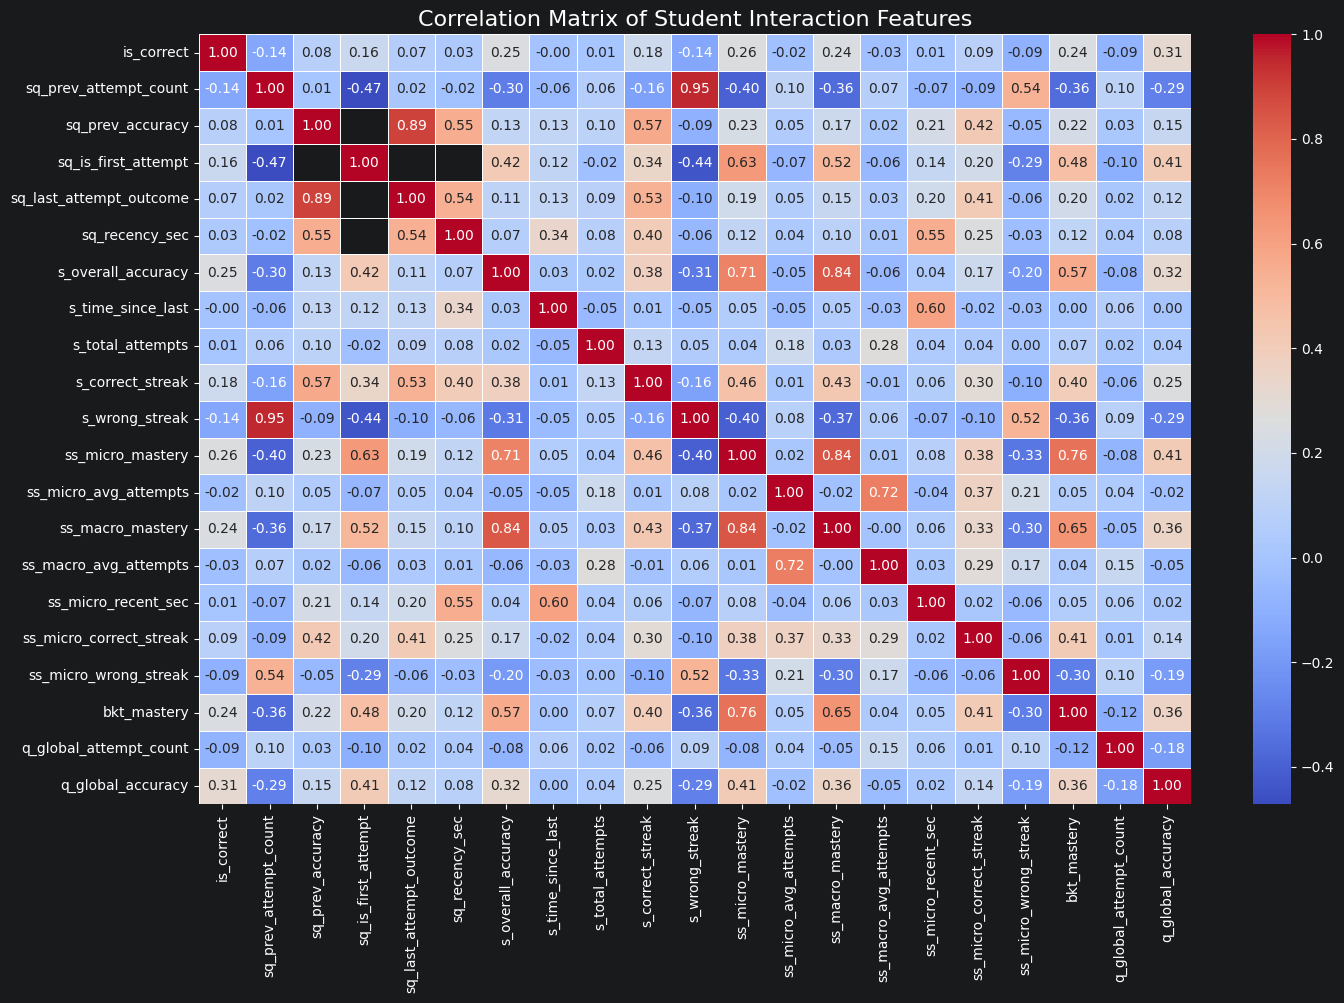

In [5]:
# Retrieve dataset
dataset = pd.read_parquet(CLEANED_DIRECTORY + "train.parquet")

# Only retain numerical values (but exclude the IDs)
corr_data = dataset.select_dtypes(include=['number']).drop(columns=[c for c in ['log_id', 'student_id', 'problem_id'] if c in dataset.columns])

# Create and plot the correlation matrix
corr_matrix = corr_data.corr()
plt.figure(figsize=(16, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title("Correlation Matrix of Student Interaction Features", fontsize=16)
plt.show()

### Overlay Density Plot to understand predictive power

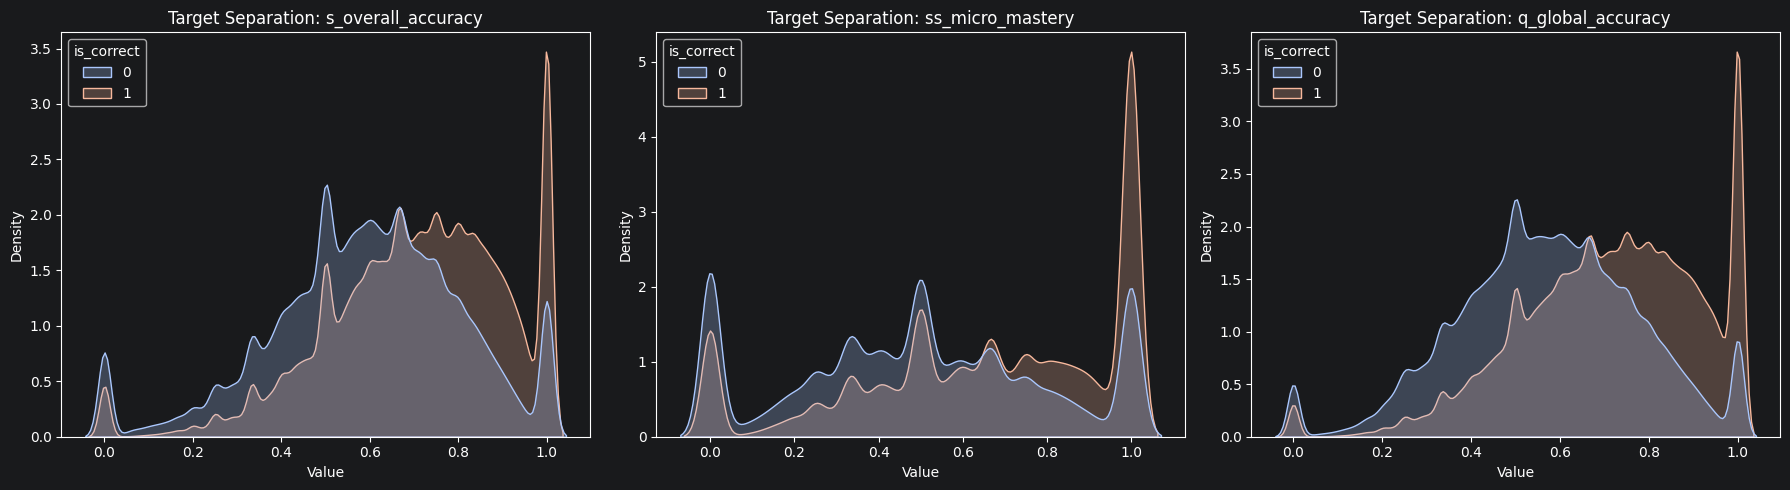

In [6]:
# Retrieve dataset
dataset = pd.read_parquet(CLEANED_DIRECTORY + "train.parquet")

# Some strong attributes contributing to the model
features_to_plot = ['s_overall_accuracy', 'ss_micro_mastery', 'q_global_accuracy']

# Create the grids
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot the strong attributes
for i, feature in enumerate(features_to_plot):
    sns.kdeplot(data=dataset, x=feature, hue='is_correct', fill=True,
                common_norm=False, palette='coolwarm', ax=axes[i])
    axes[i].set_title(f'Target Separation: {feature}')
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Density')

# Show the graph
plt.tight_layout()
plt.show()

## Step 2: Understanding Data Distribution

### Frequency Distribution for `problem_type`

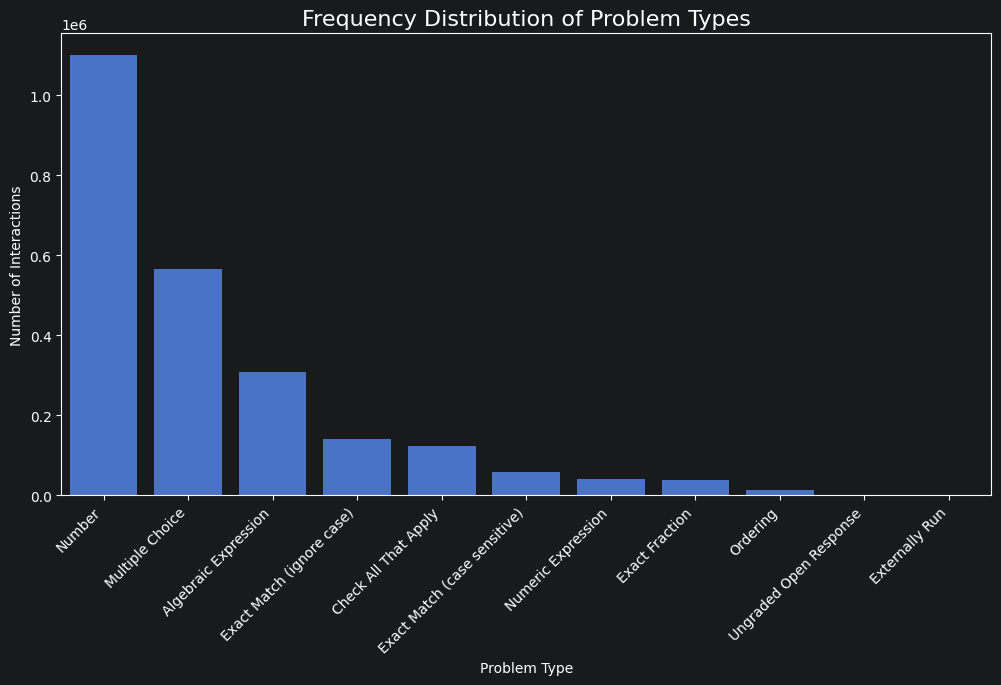

In [7]:
# Retrieve dataset
dataset = pd.read_parquet(CLEANED_DIRECTORY + "train.parquet")

# Plot the frequency distribution
plt.figure(figsize=(12, 6))
sns.countplot(data=dataset,
              x='problem_type',
              order=dataset['problem_type'].value_counts().index,
)
plt.title("Frequency Distribution of Problem Types", fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.ylabel("Number of Interactions")
plt.xlabel("Problem Type")
plt.show()

### Boxplot for Skewness

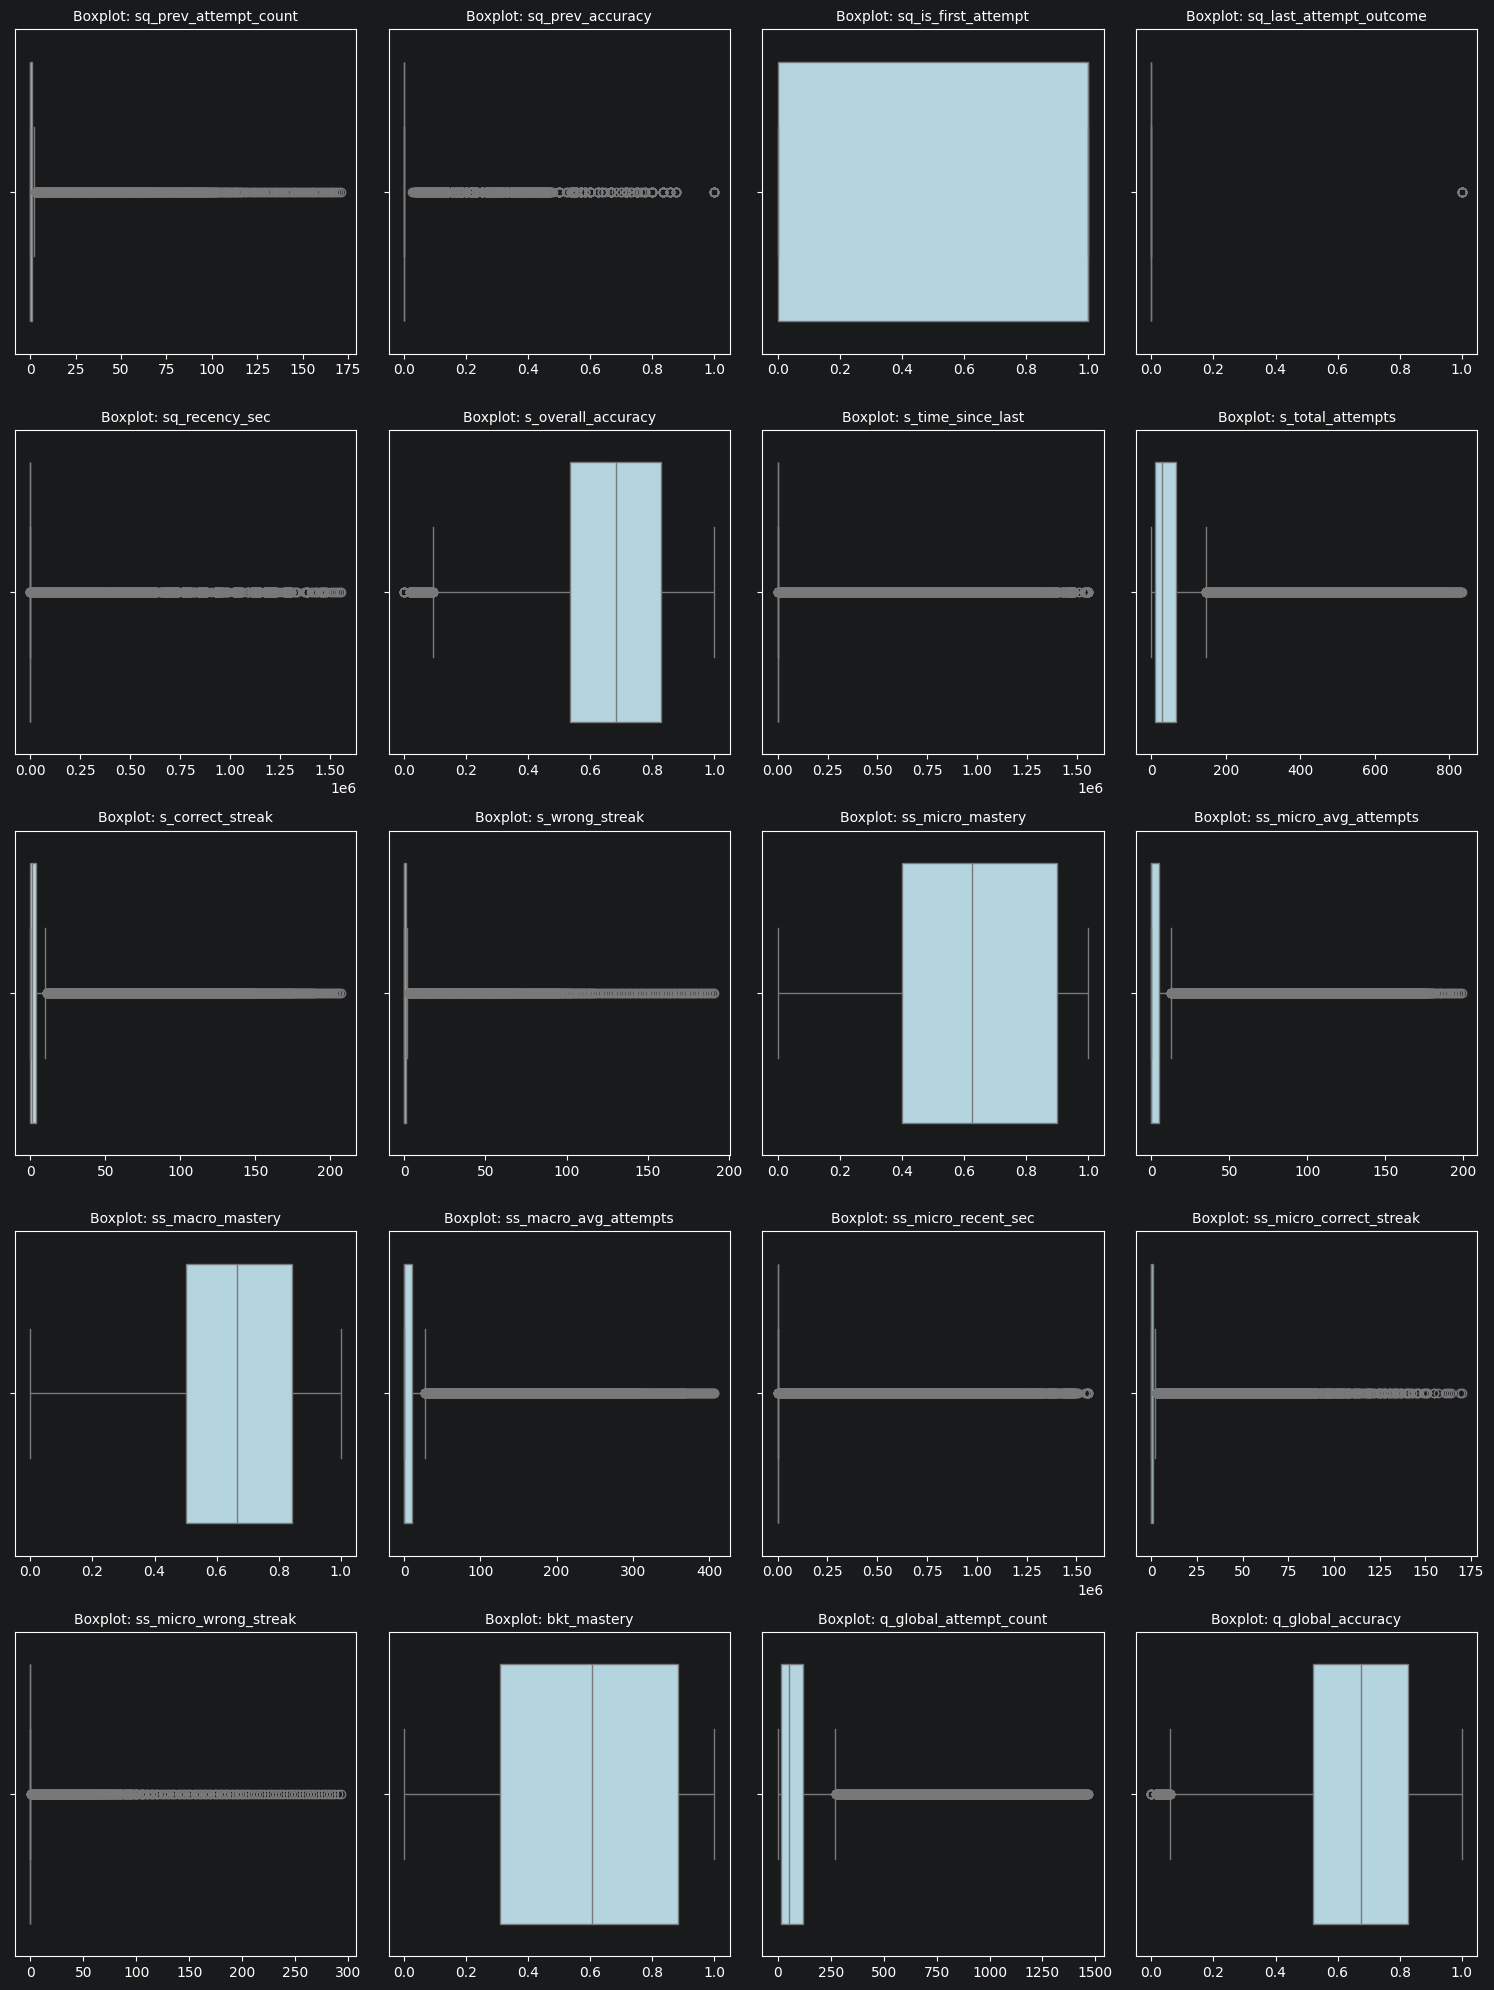

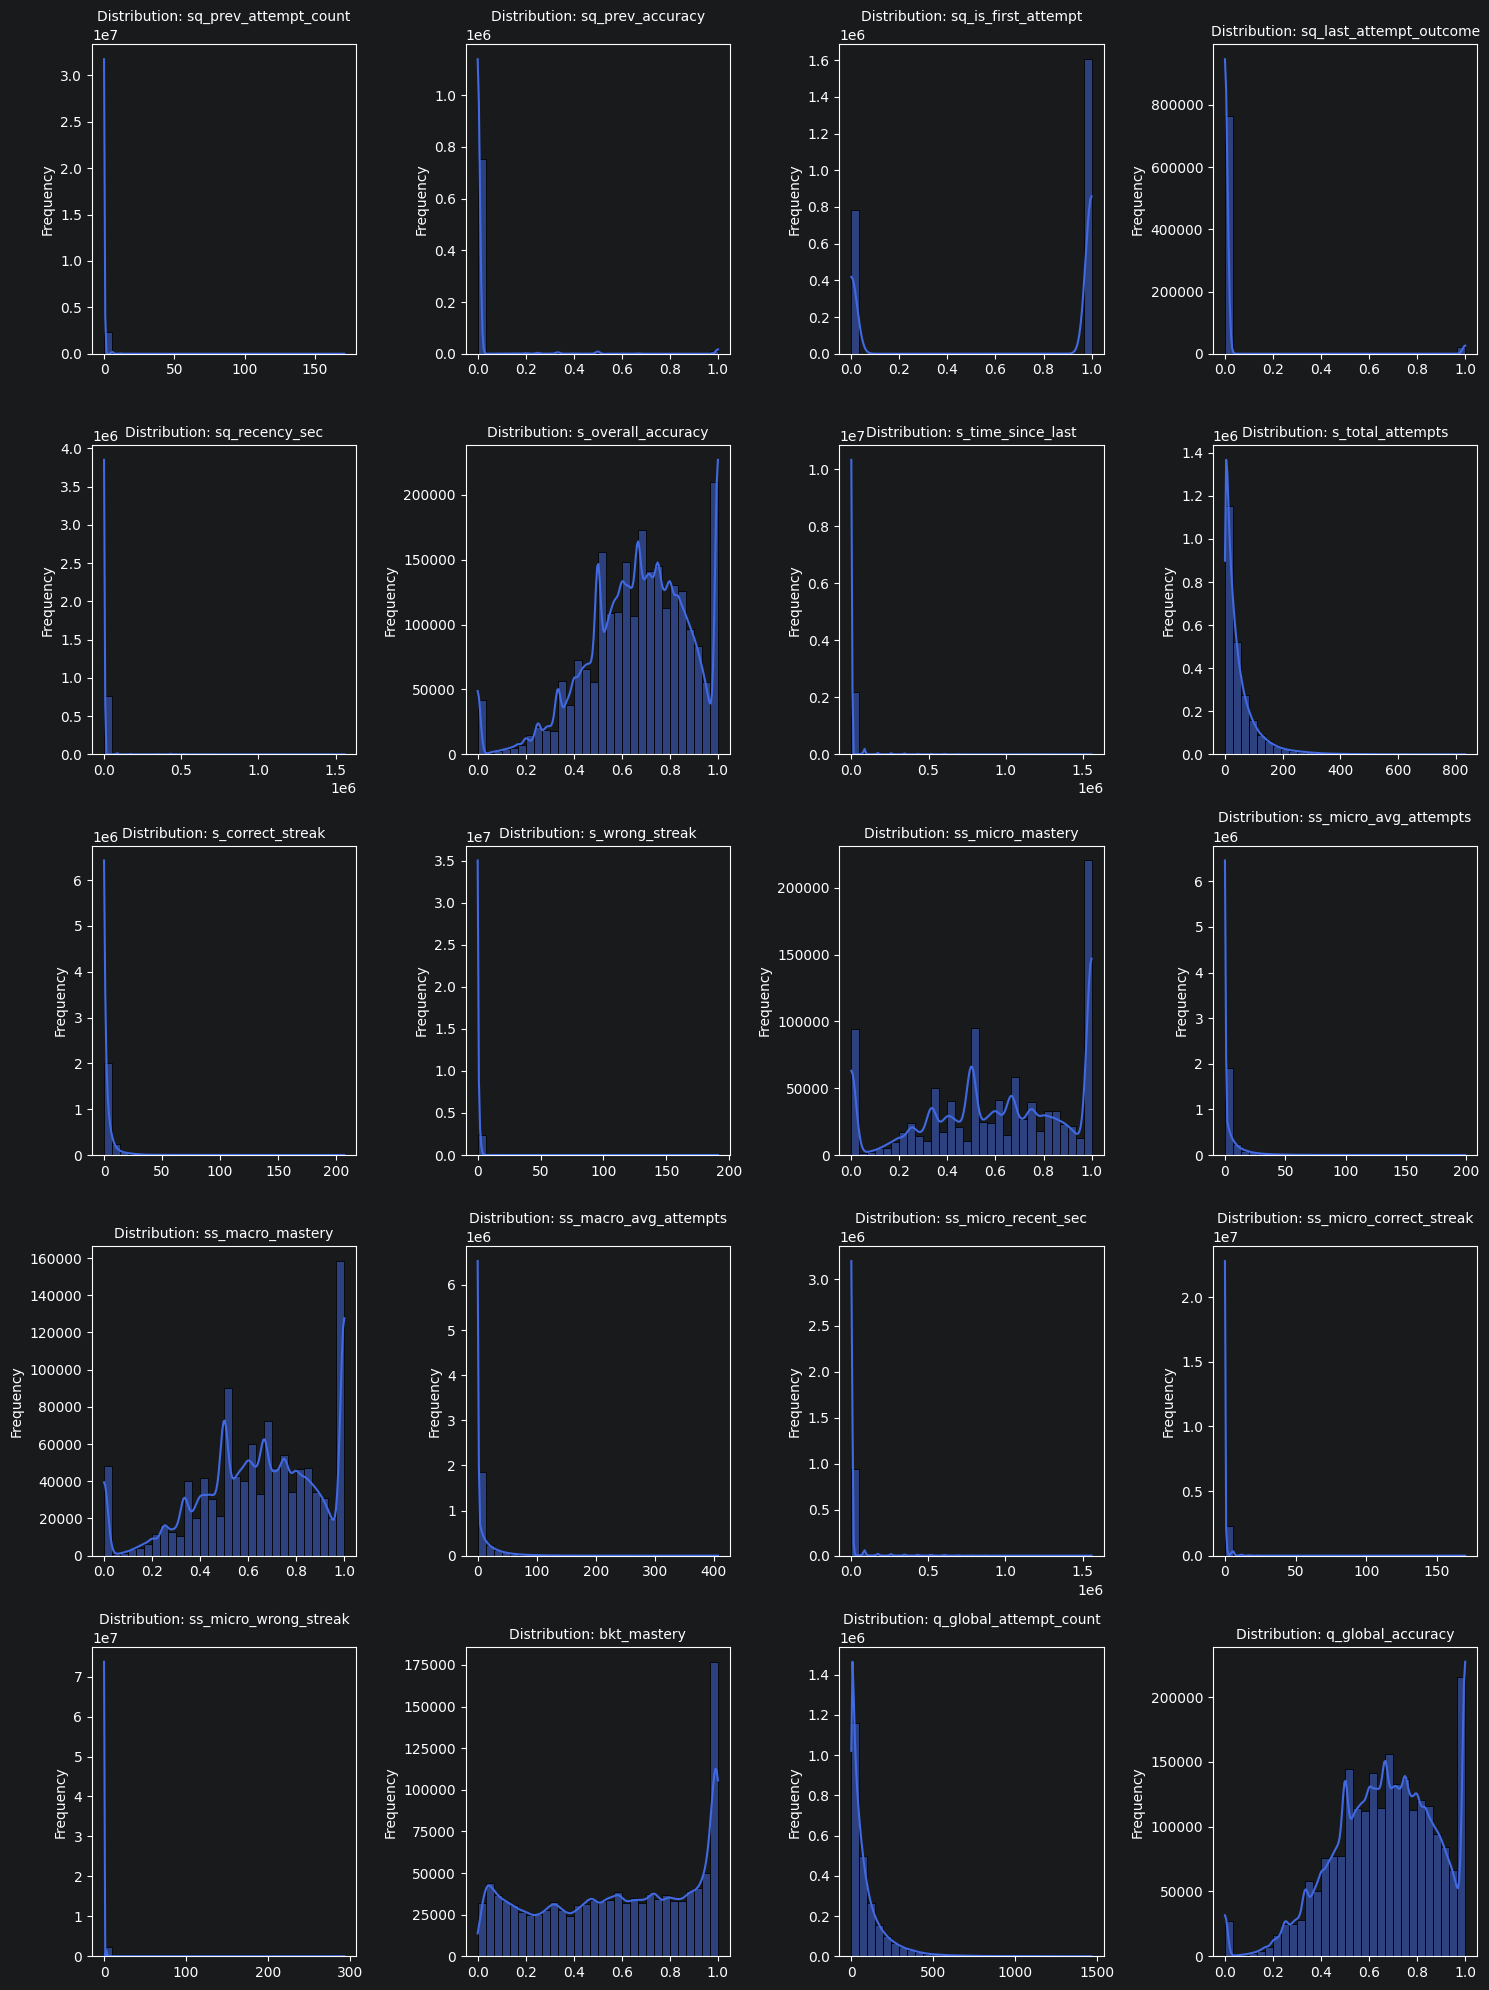

In [8]:
# Retrieve dataset
dataset = pd.read_parquet(CLEANED_DIRECTORY + "train.parquet")

# Remove IDs and target variables
num_cols = dataset.select_dtypes(include=['number']).drop(columns=[c for c in ['log_id', 'student_id', 'problem_id', 'is_correct'] if c in dataset.columns]).columns

# Calculate the grid size
n_cols = 4
n_rows = math.ceil(len(num_cols) / n_cols)

# --- Boxplot ---
# Create grids
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

# Loop through each column and draw a boxplot
for i, col in enumerate(num_cols):
    sns.boxplot(data=dataset, x=col, ax=axes[i], color='lightblue')
    axes[i].set_title(f'Boxplot: {col}', fontsize=10)
    axes[i].set_xlabel('')

# Hide empty subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Show the boxplot
plt.tight_layout()
plt.show()

# --- Histogram ---
# Reset the grids
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

# Loop through each attribute
for i, col in enumerate(num_cols):
    sns.histplot(data=dataset, x=col, bins=30, kde=True, ax=axes[i], color='royalblue')
    axes[i].set_title(f'Distribution: {col}', fontsize=10)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Frequency')

# Hide empty subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Show the histogram
plt.tight_layout()
plt.show()